# 16 - Head-to-Head Against Recent DAS Methods, Under Our Protocol

## The three objections this answers

**R1C4** - coverage of the state of the art is too thin; 2024-onward methods should be
compared under identical partitions, preprocessing and metrics.

**R2C1** - S2-DyGNN reports 94.0% accuracy, 86.6% macro-F1 and 55.7% openclose F1 on the
same nine-class Tomasov dataset, against our 90.71 / 81.98 / 4.4. The partitions differ,
which is exactly why a true head-to-head is required.

**R2C2** - a recent spatio-spectral graph model reaches openclose F1 above 0.55. That
weakens our claim that the class is unrecoverable once overlap leakage is removed. The
manuscript must separate *dataset confounding* from *model inadequacy*.

## Why S2-DyGNN cannot be dismissed on leakage grounds

Their Section 6.1 states the protocol: 8192-sample windows, 2048-sample shift,
chronological allocation of the first 80% to training with validation and test taking 10%
each, **separated by a five-window safety margin**. At a 2048 shift, five windows is
10{,}240 raw samples, which exceeds the 8192-sample window length. Their partition is
sample-disjoint at the boundaries, like ours, so their 94.0% is not a leakage artefact.

## Design

| Model | Family | Input | Published (their protocol) |
|---|---|---|---|
| **S2-DyGNN** | dynamic graph | 17-channel patch, STFT 1024/256 | 94.0 acc / 86.6 F1 / 55.7 openclose |
| **DASViT1D** | transformer on spectra | MFCC+RDFT+DWT fused to 8192 | 93.5 acc / 91.29 F1 |
| **DAStatFormer** | gated multibranch transformer | 24 statistics per channel | 99.93 acc / 99.96 F1 (Tomasov), 99.48 (Cao) |
| **GCN** | static graph | 17-channel patch, fixed adjacency | 85.3 acc / 75.5 F1 / 37.2 openclose |
| **GAT** | attention graph | 17-channel patch, learned attention | 81.2 acc / 67.3 F1 / 28.6 openclose |
| **Ours** | multi-domain features | 1002 features, LightGBM | 90.71 acc / 81.98 F1 / 4.4 openclose |

The 1D CNN baseline of Tomasov et al. is already measured in notebook 11 and is carried
into the comparison table from there rather than retrained. GCN and GAT are the static-graph
comparators S2-DyGNN benchmarks against in its own Table 3; their published openclose F1
rises with the amount of inter-node structure each model can express (28.6, 37.2, then 55.7
when the topology is recomputed per frame), and reproducing that ordering under our
partition is what turns R2C2 into a test of the mechanism rather than one data point.

## Full data, both arms

Every model is trained twice on **identical rows**, using the **complete manifest** - the
same 148,229 / 12,895 / 11,334 Tomasov windows and 12,155 / 1,460 / 1,803 Cao records
behind our own headline figures:

* **arm A** - our leakage-safe split (blocked segments + guard band on Tomasov,
  session-grouped on Cao)
* **arm B** - stratified random split of those same rows

Arm A is the head-to-head R2C1 asks for. Arm B explains their published numbers.

Our own pipeline is **not** retrained here. Its numbers are read from the stored model card
so the comparison quotes exactly the figures the manuscript reports.

## Which protocol each arm uses

Arm A does not re-derive a partition. It reads `split_manifest.parquet` and inherits the
assignment used for every other result in this study. Section 1 runs the notebook-02 audits
on the exact rows and refuses to continue if any fail, and it measures arm B's contamination
rather than assuming it.

## Three asymmetries to declare

1. **Cao arm A is session-grouped, not date-grouped.** That is the protocol this paper
   proposes and the one R2C1 asks the comparison to use, but Section 4.8 shows that holding
   out whole acquisition *dates* is a materially harder test. The Cao head-to-head therefore
   measures within-campaign performance and should be reported as such.
2. **Spatial context differs by design.** The graph models see the seventeen adjacent
   channels their source specifies; on Cao all twelve released channels are used. Our own
   spatial descriptors were computed from a thirty-two-channel patch on Tomasov, so on that
   dataset our method has the wider spatial view, not a narrower one.
3. **Preprocessing is matched, which is not the same as faithful.** With `PREPROCESS = True`
   every architecture receives the chain our own features receive: demean, 20-2000 Hz
   band-pass, per-channel z-score. That is what R2C1 asks for, and it removes an asymmetry
   the manuscript carries - the CNN baselines in Section 4.9 were trained on raw records
   while the 1002 features were not. It costs the competitors something specific:
   per-channel z-scoring fixes the standard deviation at one, so DAStatFormer's amplitude
   attributes carry no information. Our own time-domain features lose the same quantity, so
   the constraint is symmetric, but it should be stated rather than discovered.

Every architectural constant is taken from the source papers and recorded in
`dasfe.sota.ASSUMPTIONS`. Training length is the one deliberate exception: all models get
30 epochs with early stopping at patience 10, so that budget is not a confound.

In [1]:
import sys, json, time, gc, shutil
from pathlib import Path
# No machine-specific path: the kernel starts in Experiment/ (or the repo root).
EXPERIMENT_DIR = Path.cwd() if (Path.cwd() / "dasfe").is_dir() else Path.cwd() / "Experiment"
if str(EXPERIMENT_DIR) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from dasfe import config as C, evaluate as EV, preprocess as pp
from dasfe import splits as SPL   # not S: build_cache returns a stats array called S
from dasfe import sota as SO

sns.set_theme(style="whitegrid", context="notebook")

# ----------------------------- CONFIGURE ME -----------------------------
# SMOKE exercises every code path on a tiny sample and writes NOTHING to disk -
# no cache, no CSV, no figure. Use it after any change to this notebook or to
# dasfe/sota.py, then set it back to False.
SMOKE = False

DATASETS  = ("tomasov", "cao")
MODELS    = ("S2-DyGNN", "DASViT1D", "DAStatFormer", "GCN", "GAT")
ARMS      = ("A_blocked", "B_random")

# None uses the complete manifest - the same rows behind our own headline
# figures. Set to a dict like {"train": 8000, "val": None, "test": None} to cap
# training only; val and test should stay uncapped so the test metrics remain
# directly comparable to the manuscript.
PER_CLASS = None

# Spatial neighbourhood. 17 is S2-DyGNN's stated topology; Cao releases 12
# channels per record, so all 12 are used there.
NODES     = {"tomasov": 17, "cao": 12}

# One budget for every architecture, so training length cannot confound the
# comparison. Early stopping watches validation macro-F1.
EPOCHS    = 30
PATIENCE  = 10

# Match the preprocessing our own 1002 features receive (R2C1).
PREPROCESS = True

REBUILD_CACHE = False    # True forces re-extraction
RESUME        = True     # skip (dataset, arm, model) triples already completed
MIN_FREE_GB   = 8.0      # headroom demanded on top of the cache itself
# ------------------------------------------------------------------------

SAVE = not SMOKE
if SMOKE:
    PER_CLASS = {"train": 30, "val": 10, "test": 10}
    EPOCHS, PATIENCE = 1, 1
    print("SMOKE MODE: tiny sample, 1 epoch, NOTHING written to disk.")
    print("Nothing here is a result. Set SMOKE = False for the real run.")

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, "|", torch.cuda.get_device_name(0) if dev == "cuda" else "")
out_dir = C.results_dir("shared", "16_sota_head_to_head")
print("output:", out_dir, "(writes disabled)" if SMOKE else "")


def save_csv(df, name, index=False):
    if SAVE:
        df.to_csv(out_dir / name, index=index)


def save_json(obj, name):
    if SAVE:
        (out_dir / name).write_text(json.dumps(obj, indent=2), encoding="utf-8")


def save_fig(fig, name):
    if SAVE:
        fig.savefig(out_dir / name, dpi=200, bbox_inches="tight")


PUBLISHED = pd.DataFrame([
    {"model": "S2-DyGNN", "dataset": "tomasov", "accuracy": 94.0,
     "f1_macro": 86.6, "openclose_f1": 55.7,
     "their_protocol": "chronological 80/10/10, 5-window margin (sample-disjoint)"},
    {"model": "DASViT1D", "dataset": "tomasov", "accuracy": 93.5,
     "f1_macro": 91.29, "openclose_f1": np.nan,
     "their_protocol": "80/10/10 over pre-segmented overlapping windows"},
    {"model": "DAStatFormer", "dataset": "tomasov", "accuracy": 99.93,
     "f1_macro": 99.96, "openclose_f1": np.nan,
     "their_protocol": "random 10% validation split"},
    {"model": "DAStatFormer", "dataset": "cao", "accuracy": 99.48,
     "f1_macro": np.nan, "openclose_f1": np.nan,
     "their_protocol": "released 8:2 split (423/441 sessions straddle it)"},
] + [
    {"model": k, "dataset": "tomasov", "accuracy": v["accuracy"],
     "f1_macro": v["f1_macro"], "openclose_f1": v["openclose_f1"],
     "their_protocol": "chronological 80/10/10, 5-window margin (sample-disjoint)"}
    for k, v in SO.CMP_PUBLISHED.items() if k in ("GCN", "GAT")
])
display(PUBLISHED)
save_csv(PUBLISHED, "published_reference.csv")

_assump = dict(SO.ASSUMPTIONS)
_assump["this_notebook"] = {
    "preprocessing": ("demean, 20-2000 Hz band-pass, per-channel z-score applied to "
                      "every architecture" if PREPROCESS else "raw records"),
    "training_budget": f"{EPOCHS} epochs, early stopping patience {PATIENCE}, "
                       f"identical for every architecture",
    "per_class_cap": PER_CLASS,
    "nodes": NODES,
    "arm_A_split": "inherited from split_manifest.parquet, audited in section 1",
    "ours_not_retrained": ("our pipeline's figures are read from "
                           "07_final/full_1002/model_card.json so the table quotes "
                           "exactly what the manuscript reports"),
    "cnn_lstm_dropped": ("the 1D CNN of Tomasov et al. is carried from notebook 11 "
                         "and covers the convolutional baseline"),
}
save_json(_assump, "sota_assumptions.json")

device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU
output: C:\Users\irvin\Desktop\THESIS-MASTERS-UTP\Rerun\fixed\Results\shared\16_sota_head_to_head 


,model,dataset,accuracy,f1_macro,openclose_f1,their_protocol
0,S2-DyGNN,tomasov,94.00,86.60,55.7,"chronological 80/10/10, 5-window margin (sampl..."
1,DASViT1D,tomasov,93.50,91.29,NaN,80/10/10 over pre-segmented overlapping windows
2,DAStatFormer,tomasov,99.93,99.96,NaN,random 10% validation split
3,DAStatFormer,cao,99.48,NaN,NaN,released 8:2 split (423/441 sessions straddle it)
4,GAT,tomasov,81.20,67.30,28.6,"chronological 80/10/10, 5-window margin (sampl..."
5,GCN,tomasov,85.30,75.50,37.2,"chronological 80/10/10, 5-window margin (sampl..."


## 1. Build the population, audit it, cache the representations

One extraction pass per dataset writes three representations: the multi-channel patch for
the graph models, the fused MFCC+RDFT+DWT vector for DASViT1D, and the 24 statistical
attributes per channel for DAStatFormer.

At full size the Tomasov patch cache is about 48 GB, so it is memory-mapped rather than
held in RAM and a pre-flight check refuses to start if the disk cannot take it. In smoke
mode everything stays in memory and nothing is written.

In [2]:
def stratified_random_split(df, seed, fractions=C.SPLIT_FRACTIONS):
    out = np.empty(len(df), dtype=object)
    r = np.random.default_rng(seed)
    for lab, idx in df.groupby("label").indices.items():
        idx = np.asarray(idx).copy()
        r.shuffle(idx)
        n = len(idx)
        n_tr = int(round(fractions[0] * n))
        n_va = int(round(fractions[1] * n))
        out[idx[:n_tr]] = "train"
        out[idx[n_tr:n_tr + n_va]] = "val"
        out[idx[n_tr + n_va:]] = "test"
    return np.asarray(out, dtype=object)


def audit_split(sub, ds):
    # Prove arm A is still leakage-safe on the exact rows used here, and measure
    # arm B rather than assuming it. Capping samples within each (label, split)
    # cell and never reassigns a row, so it can only shrink a footprint - but an
    # unverified protocol claim is what this paper is about.
    rows = []

    def check(name, fn):
        try:
            fn()
            rows.append({"dataset": ds, "check": name, "result": "PASS", "detail": ""})
        except AssertionError as exc:
            rows.append({"dataset": ds, "check": name, "result": "FAIL",
                         "detail": str(exc)[:160]})

    group_key = "group_id" if ds == "tomasov" else "session_id"
    check(f"arm A: {group_key} disjoint across splits",
          lambda: SPL.assert_group_disjoint(sub, group_key, "split_A"))
    check("no duplicate sample_id", lambda: SPL.assert_no_duplicate_ids(sub))
    if ds == "tomasov":
        check("arm A: no raw-sample overlap between splits",
              lambda: SPL.assert_no_sample_overlap(sub, "split_A"))
        bpw = C.WIN_LEN // C.WIN_HOP
        hit = tot = 0
        for _, g in sub.groupby("recording_id", sort=False):
            n = int(g["block"].max()) + bpw + 1
            cov = np.zeros(n, dtype=bool)
            b_tr = g.loc[g["split_B"] == "train", "block"].to_numpy()
            for off in range(bpw):
                cov[b_tr + off] = True
            b_te = g.loc[g["split_B"] == "test", "block"].to_numpy()
            if b_te.size == 0:
                continue
            h = np.zeros(b_te.size, dtype=bool)
            for off in range(bpw):
                h |= cov[b_te + off]
            hit += int(h.sum())
            tot += int(b_te.size)
        rows.append({"dataset": ds,
                     "check": "arm B: test windows sharing raw samples with train",
                     "result": f"{100*hit/max(tot,1):.1f}%",
                     "detail": f"{hit:,} of {tot:,}"})
    else:
        spanning = int((sub.groupby("session_id")["split_B"].nunique() > 1).sum())
        total = int(sub["session_id"].nunique())
        rows.append({"dataset": ds, "check": "arm B: sessions spanning train and test",
                     "result": f"{spanning}/{total}",
                     "detail": f"{100*spanning/max(total,1):.1f}% of sessions"})
    return pd.DataFrame(rows)


def build_manifest(ds):
    mani = pd.read_parquet(C.results_dir(ds, "01_splits") / "split_manifest.parquet")
    if PER_CLASS is None:
        sub = mani.copy()
    else:
        parts = []
        for (lab, sp), g in mani.groupby(["label", "split"]):
            cap = PER_CLASS.get(sp)
            n = len(g) if cap is None else min(cap, len(g))
            if n:
                parts.append(g.sample(n, random_state=C.SEED))
        sub = pd.concat(parts)
    sub = sub.sort_values(["h5_path", "t0", "locus"] if ds == "tomasov" else "path")
    sub = sub.reset_index(drop=True)
    sub["split_A"] = sub["split"].to_numpy().astype(object)
    sub["split_B"] = stratified_random_split(sub, C.SEED + 404)

    audit = audit_split(sub, ds)
    display(audit)
    failed = audit[audit["result"] == "FAIL"]
    if len(failed):
        raise AssertionError(
            f"{ds}: arm A is not leakage-safe - " +
            "; ".join(failed["check"] + ": " + failed["detail"]))
    return sub


def cache_bytes(ds, n):
    nn_ = NODES[ds]
    win = C.DATASETS[ds].win_len
    return n * nn_ * win * 2 + n * SO.DASVIT_DIM * 2 + n * nn_ * 24 * 4


def preflight(sizes):
    need = sum(cache_bytes(ds, n) for ds, n in sizes.items())
    print("cache budget:")
    for ds, n in sizes.items():
        print(f"  {ds:8s} {n:>8,} windows -> {cache_bytes(ds, n)/1e9:6.2f} GB")
    print(f"  {'TOTAL':8s} {'':>8s}    {need/1e9:6.2f} GB")
    if not SAVE:
        print("  smoke mode: held in RAM, nothing written")
        return
    free = shutil.disk_usage(out_dir).free
    print(f"  free on volume    {free/1e9:6.2f} GB")
    if free < need + MIN_FREE_GB * 1e9:
        raise MemoryError(
            f"need {need/1e9:.1f} GB plus {MIN_FREE_GB:.0f} GB headroom, "
            f"{free/1e9:.1f} GB free. Lower PER_CLASS, e.g. "
            f'{{"train": 8000, "val": None, "test": None}}.')

In [3]:
def open_array(name, shape, dtype):
    # Memory-mapped on disk for the real run; plain RAM for smoke, which writes
    # nothing.  The patch cache alone is ~48 GB at full Tomasov size.
    if not SAVE:
        return np.empty(shape, dtype=dtype)
    return np.lib.format.open_memmap(out_dir / name, mode="w+",
                                     dtype=dtype, shape=shape)


def build_cache(ds, sub):
    spec = C.DATASETS[ds]
    n_nodes, win, n = NODES[ds], spec.win_len, len(sub)
    tag = ("pp" if PREPROCESS else "raw")
    names = {k: f"{k}_{ds}_{tag}.npy" for k in ("patches", "dasvit", "stats")}

    if SAVE and not REBUILD_CACHE and all((out_dir / v).exists() for v in names.values()):
        P = np.load(out_dir / names["patches"], mmap_mode="r")
        if P.shape == (n, n_nodes, win):
            print(f"  reusing cached arrays for {ds}")
            return (P,
                    np.load(out_dir / names["dasvit"], mmap_mode="r"),
                    np.load(out_dir / names["stats"], mmap_mode="r"))
        print("  cache shape mismatch, rebuilding")

    P = open_array(names["patches"], (n, n_nodes, win), np.float16)
    V = open_array(names["dasvit"], (n, SO.DASVIT_DIM), np.float16)
    S = open_array(names["stats"], (n, n_nodes, 24), np.float32)

    t0 = time.perf_counter()
    if ds == "tomasov":
        reader, cur = None, None
        try:
            for i, r in enumerate(sub.itertuples()):
                if r.h5_path != cur:
                    if reader is not None:
                        reader.close()
                    reader = pp.TomasovReader(r.h5_path)
                    cur = r.h5_path
                    print(f"    opened {Path(cur).name}", flush=True)
                patch = reader.read_patch(int(r.t0), int(r.locus), win, n_nodes)
                if PREPROCESS:
                    patch = pp.preprocess_patch(patch, reader.fs)
                P[i] = patch.astype(np.float16)
                V[i] = SO.dasvit1d_features(patch[n_nodes // 2], reader.fs).astype(np.float16)
                S[i] = SO.dastatformer_features(patch, reader.fs)
                if (i + 1) % 5000 == 0:
                    el = time.perf_counter() - t0
                    print(f"    {i+1:,}/{n:,}  {el/60:.1f} min elapsed, "
                          f"{el/(i+1)*(n-i-1)/60:.1f} min left", flush=True)
        finally:
            if reader is not None:
                reader.close()
    else:
        for i, r in enumerate(sub.itertuples()):
            patch = pp.load_cao_window(r.path, win)
            ref = pp.cao_reference_channel(patch)      # choose before z-scoring
            if PREPROCESS:
                patch = pp.preprocess_patch(patch, spec.fs)
            P[i] = patch.astype(np.float16)
            V[i] = SO.dasvit1d_features(patch[ref], spec.fs).astype(np.float16)
            S[i] = SO.dastatformer_features(patch, spec.fs)
            if (i + 1) % 2000 == 0:
                print(f"    {i+1:,}/{n:,}", flush=True)

    if SAVE:
        for a in (P, V, S):
            a.flush()
    print(f"  extracted in {(time.perf_counter()-t0)/60:.1f} min")
    return P, V, S


MANI = {ds: build_manifest(ds) for ds in DATASETS}
preflight({ds: len(m) for ds, m in MANI.items()})

CACHE = {}
for ds in DATASETS:
    print(f"=== {ds} ===")
    sub = MANI[ds]
    P, V, S = build_cache(ds, sub)
    CACHE[ds] = {"manifest": sub, "patch": P, "fused1d": V, "stats": S,
                 "y": sub["label"].to_numpy(),
                 "classes": sorted(sub["label"].unique())}
    print(pd.crosstab(sub["label"], sub["split_A"]))

,dataset,check,result,detail
0,tomasov,arm A: group_id disjoint across splits,PASS,
1,tomasov,no duplicate sample_id,PASS,
2,tomasov,arm A: no raw-sample overlap between splits,PASS,
3,tomasov,arm B: test windows sharing raw samples with t...,100.0%,"17,245 of 17,246"


,dataset,check,result,detail
0,cao,arm A: session_id disjoint across splits,PASS,
1,cao,no duplicate sample_id,PASS,
2,cao,arm B: sessions spanning train and test,426/441,96.6% of sessions


cache budget:
  tomasov   172,458 windows ->  51.14 GB
  cao        15,418 windows ->   3.30 GB
  TOTAL                 54.44 GB
  free on volume    474.82 GB
=== tomasov ===
  reusing cached arrays for tomasov
split_A       test  train   val
label                          
car           1772  25303  1934
construction  2232  23041  2147
fence         1983  33432  2700
longboard      581  11671  1052
manipulation   867  13519  1163
openclose      198   5280   336
regular       1111  10272   966
running        929  10811  1057
walk          1661  14900  1540
=== cao ===
  reusing cached arrays for cao
split_A     test  train  val
label                       
background   227   2311  407
dig          370   1931  211
knock        622   1802  106
shake        134   2533   61
walk         232   1844  374
water        218   1734  301


## 2. Training harness

One budget for every architecture: 30 epochs, early stopping at patience 10 on validation
macro-F1, best checkpoint evaluated on test. Each epoch prints its loss, validation score
and elapsed time, so a long run can be monitored.

Parameter count, model size, training time and inference latency are recorded alongside
the metrics, because the comparison the paper needs is cost as well as accuracy.

In [4]:
class ArrayRows(Dataset):
    # Lazy row indexing over a memmap. A boolean mask would copy the whole split.
    def __init__(self, arr, yi, idx, scale=None):
        self.arr, self.yi, self.idx, self.scale = arr, yi, idx, scale

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, k):
        j = self.idx[k]
        x = np.asarray(self.arr[j], dtype=np.float32)
        if self.scale is not None:
            x = (x - self.scale[0]) / self.scale[1]
        return torch.from_numpy(x), int(self.yi[j])


def fit_scaler(arr, idx, kind):
    # Streaming mean/std over the training rows only. The graph models normalise
    # inside their own STFT and BatchNorm front end, so they need no scaler.
    if kind == "patch":
        return None
    n, s, ss = 0, None, None
    for i in range(0, len(idx), 4096):
        blk = np.asarray(arr[idx[i:i+4096]], dtype=np.float64)
        a, b = blk.sum(axis=0), (blk ** 2).sum(axis=0)
        s = a if s is None else s + a
        ss = b if ss is None else ss + b
        n += len(blk)
    mu = s / n
    sd = np.sqrt(np.maximum(ss / n - mu ** 2, 0.0))
    sd[sd < 1e-8] = 1.0
    return mu.astype(np.float32), sd.astype(np.float32)


@torch.no_grad()
def predict(net, loader):
    net.eval()
    out = []
    for xb, _ in loader:
        out.append(net(xb.to(dev)).argmax(1).cpu().numpy())
    return np.concatenate(out) if out else np.array([], dtype=int)


def train_sota(model_name, ds, arm):
    cfg = SO.SOTA_MODELS[model_name]
    d = CACHE[ds]
    classes = d["classes"]
    arr = d[cfg["input"]]
    col = "split_A" if arm.startswith("A") else "split_B"
    sp = d["manifest"][col].to_numpy()
    yi = np.array([classes.index(v) for v in d["y"]])
    i_tr = np.flatnonzero(sp == "train")
    i_va = np.flatnonzero(sp == "val")
    i_te = np.flatnonzero(sp == "test")

    scale = fit_scaler(arr, i_tr, cfg["input"])
    torch.manual_seed(C.SEED)
    if cfg["input"] == "patch":
        net = cfg["build"](len(classes), n_nodes=NODES[ds])
    elif cfg["input"] == "stats":
        net = cfg["build"](len(classes), NODES[ds])
    else:
        net = cfg["build"](len(classes))
    net = net.to(dev)

    n_par = sum(p.numel() for p in net.parameters())
    size_mb = sum(p.numel() * p.element_size() for p in net.parameters()) / 1e6

    batch = cfg["batch"]
    opt_cls = torch.optim.AdamW if cfg["optim"] == "adamw" else torch.optim.Adam
    opt = opt_cls(net.parameters(), lr=cfg["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
    lossf = nn.CrossEntropyLoss()          # unweighted, as the source papers state

    dl_tr = DataLoader(ArrayRows(arr, yi, i_tr, scale), batch_size=batch,
                       shuffle=True, num_workers=0)
    dl_va = DataLoader(ArrayRows(arr, yi, i_va, scale), batch_size=batch * 2)
    dl_te = DataLoader(ArrayRows(arr, yi, i_te, scale), batch_size=batch * 2)

    print(f"  {model_name} / {ds} / {arm}: {n_par:,} params, {size_mb:.2f} MB, "
          f"{len(i_tr):,} train / {len(i_va):,} val / {len(i_te):,} test", flush=True)

    best_f1, best_state, best_ep, hist = -1.0, None, -1, []
    t0 = time.perf_counter()
    for ep in range(EPOCHS):
        net.train()
        tot = 0.0
        for xb, yb in dl_tr:
            xb, yb = xb.to(dev), yb.to(dev)
            opt.zero_grad()
            loss = lossf(net(xb), yb)
            loss.backward()
            if model_name == "DAStatFormer":
                nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            tot += float(loss.detach()) * len(yb)
        tr_loss = tot / max(len(i_tr), 1)
        hist.append(tr_loss)

        pv = predict(net, dl_va)
        m = EV.score_all(d["y"][i_va], np.array([classes[i] for i in pv]), labels=classes)
        val_f1 = 100 * m["f1_macro"]
        sched.step(tr_loss)

        flag = ""
        if val_f1 > best_f1:
            best_f1, best_ep = val_f1, ep
            best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
            flag = "  <- best"
        print(f"    epoch {ep+1:>3}/{EPOCHS}  loss {tr_loss:.4f}  val F1 {val_f1:6.2f}"
              f"  {(time.perf_counter()-t0)/60:6.1f} min{flag}", flush=True)

        if ep - best_ep >= PATIENCE:
            print(f"    early stop: no improvement for {PATIENCE} epochs", flush=True)
            break
    train_s = time.perf_counter() - t0

    if best_state is not None:
        net.load_state_dict(best_state)
    t1 = time.perf_counter()
    y_pred = np.array([classes[i] for i in predict(net, dl_te)])
    infer_ms = 1000 * (time.perf_counter() - t1) / max(len(i_te), 1)
    y_true = d["y"][i_te]
    mt = EV.score_all(y_true, y_pred, labels=classes)

    row = {"dataset": ds, "arm": arm, "model": model_name,
           "n_params": n_par, "size_mb": round(size_mb, 3),
           "n_train": len(i_tr), "n_test": len(i_te),
           "epochs_run": len(hist), "best_epoch": best_ep + 1,
           "val_f1_macro": round(best_f1, 3),
           "accuracy": round(100 * mt["accuracy"], 3),
           "balanced_accuracy": round(100 * mt["balanced_accuracy"], 3),
           "f1_macro": round(100 * mt["f1_macro"], 3),
           "train_seconds": round(train_s, 1),
           "infer_ms_per_sample": round(infer_ms, 4),
           "online_ms_per_window": round(infer_ms, 4)}
    print(f"  -> acc {row['accuracy']:.2f}  F1 {row['f1_macro']:.2f}  "
          f"{train_s/60:.1f} min  {infer_ms:.3f} ms/sample", flush=True)
    del net, dl_tr, dl_va, dl_te, opt
    gc.collect()
    if dev == "cuda":
        torch.cuda.empty_cache()
    return row, y_true, y_pred

## 3. Our own pipeline, read rather than retrained

The manuscript's figures come from the stored model card, so the comparison quotes exactly
what the paper reports. The online cost is the honest one: multi-domain extraction plus
classifier inference, because a deployed system pays both. The neural baselines pay only
their forward pass, which is the point of including the column.

In [5]:
def ours_row(ds):
    card_p = C.results_dir(ds, "07_final", "full_1002") / "model_card.json"
    if not card_p.exists():
        print(f"  {ds}: model_card.json not found, Ours row skipped")
        return None, None
    card = json.loads(card_p.read_text(encoding="utf-8"))

    extract_ms = np.nan
    eff = C.RESULTS_DIR / "shared" / "09_report_full_1002" / "tables" / "computational_efficiency.csv"
    if eff.exists():
        e = pd.read_csv(eff)
        sel = e[(e.dataset == ds) & (e.stage == "TOTAL")]
        if len(sel):
            extract_ms = float(sel["ms_per_window"].iloc[0])

    infer_ms = float(card["inference_ms_per_sample"])
    row = {"dataset": ds, "arm": "A_blocked", "model": "Ours (1002 features)",
           "n_params": np.nan, "size_mb": np.nan,
           "n_train": card["n_train"], "n_test": card["n_test"],
           "epochs_run": np.nan, "best_epoch": np.nan, "val_f1_macro": np.nan,
           "accuracy": card["test"]["accuracy"],
           "balanced_accuracy": card["test"]["balanced_accuracy"],
           "f1_macro": card["test"]["f1_macro"],
           "train_seconds": card["train_seconds"],
           "infer_ms_per_sample": infer_ms,
           "online_ms_per_window": round(extract_ms + infer_ms, 4)}

    pc_p = C.results_dir(ds, "07_final", "full_1002") / "per_class_report.csv"
    pc = pd.read_csv(pc_p) if pc_p.exists() else None
    return row, pc


OURS, OURS_PC = {}, {}
for ds in DATASETS:
    r, pc = ours_row(ds)
    if r is not None:
        OURS[ds] = r
        OURS_PC[ds] = pc
        print(f"  {ds}: acc {r['accuracy']:.2f}  F1 {r['f1_macro']:.2f}  "
              f"{r['n_train']:,} train  online {r['online_ms_per_window']:.2f} ms/window")

  tomasov: acc 80.52  F1 76.33  148,229 train  online 50.67 ms/window
  cao: acc 98.50  F1 98.18  12,155 train  online 36.28 ms/window


## 4. Run every model on every arm, resumably

Each completed (dataset, arm, model) is appended to `head_to_head_progress.csv` with its
per-class report and confusion matrix. Re-running the notebook skips what is already there,
so an interrupted run continues where it stopped.

In [6]:
prog_path = out_dir / "head_to_head_progress.csv"
done = set()
results = []
if RESUME and SAVE and prog_path.exists():
    prev = pd.read_csv(prog_path)
    results = prev.to_dict("records")
    done = set(zip(prev.dataset, prev.arm, prev.model))
    print(f"resuming: {len(done)} run(s) already complete")

pc_name = lambda ds, arm, m: f"per_class_{ds}_{arm}_{m.replace(' ', '_').replace('/', '-')}.csv"

for ds in DATASETS:
    for arm in ARMS:
        for name in MODELS:
            if (ds, arm, name) in done:
                print(f"skip (done): {ds} / {arm} / {name}")
                continue
            print(f"=== {ds} / {arm} / {name} ===")
            try:
                row, yt, yp = train_sota(name, ds, arm)
            except Exception as exc:
                print(f"  FAILED {type(exc).__name__}: {exc}")
                continue
            results.append(row)
            classes = CACHE[ds]["classes"]
            if SAVE:
                EV.per_class_report(yt, yp, labels=classes).to_csv(
                    out_dir / pc_name(ds, arm, name), index=False)
                EV.confusion(yt, yp, labels=classes, normalize="true").to_csv(
                    out_dir / f"confusion_{ds}_{arm}_{name}.csv")
                pd.DataFrame(results).to_csv(prog_path, index=False)

res = pd.DataFrame(results)
display(res.round(3))
save_csv(res, "head_to_head_raw.csv")

resuming: 20 run(s) already complete
skip (done): tomasov / A_blocked / S2-DyGNN
skip (done): tomasov / A_blocked / DASViT1D
skip (done): tomasov / A_blocked / DAStatFormer
skip (done): tomasov / A_blocked / GCN
skip (done): tomasov / A_blocked / GAT
skip (done): tomasov / B_random / S2-DyGNN
skip (done): tomasov / B_random / DASViT1D
skip (done): tomasov / B_random / DAStatFormer
skip (done): tomasov / B_random / GCN
skip (done): tomasov / B_random / GAT
skip (done): cao / A_blocked / S2-DyGNN
skip (done): cao / A_blocked / DASViT1D
skip (done): cao / A_blocked / DAStatFormer
skip (done): cao / A_blocked / GCN
skip (done): cao / A_blocked / GAT
skip (done): cao / B_random / S2-DyGNN
skip (done): cao / B_random / DASViT1D
skip (done): cao / B_random / DAStatFormer
skip (done): cao / B_random / GCN
skip (done): cao / B_random / GAT


,dataset,arm,model,n_params,size_mb,n_train,n_test,epochs_run,best_epoch,val_f1_macro,accuracy,balanced_accuracy,f1_macro,train_seconds,infer_ms_per_sample,online_ms_per_window
0,tomasov,A_blocked,S2-DyGNN,56329,0.225,148229,11334,11,1,70.888,70.425,67.070,67.789,11512.9,2.708,2.708
1,tomasov,A_blocked,DASViT1D,1655561,6.622,148229,11334,15,5,56.147,60.852,57.953,57.660,312.4,0.186,0.186
2,tomasov,A_blocked,DAStatFormer,16077327,64.309,148229,11334,27,17,69.756,78.366,74.501,75.316,24047.2,0.504,0.504
3,tomasov,A_blocked,GCN,48137,0.193,148229,11334,22,12,69.075,65.114,64.050,65.794,27245.7,3.931,3.931
4,tomasov,A_blocked,GAT,52361,0.209,148229,11334,13,3,73.006,75.922,71.572,72.312,16120.4,4.059,4.059
5,tomasov,B_random,S2-DyGNN,56329,0.225,137966,17246,16,6,94.003,94.955,94.105,94.272,18615.4,3.598,3.598
6,tomasov,B_random,DASViT1D,1655561,6.622,137966,17246,27,17,62.447,61.191,60.804,61.120,1041.4,0.303,0.303
7,tomasov,B_random,DAStatFormer,16077327,64.309,137966,17246,30,30,89.686,89.255,88.958,89.430,15184.5,0.198,0.198
8,tomasov,B_random,GCN,48137,0.193,137966,17246,19,9,72.981,71.622,74.261,72.836,21915.9,4.516,4.516
9,tomasov,B_random,GAT,52361,0.209,137966,17246,21,11,97.258,97.582,97.143,97.450,25489.2,4.660,4.660


## 5. The full comparison (R1C4, R2C1)

Accuracy is not the only axis the reviewers asked about. This table carries parameter
count, model size, training time, inference latency and the true online cost per window
alongside the metrics, with our pipeline included on identical test rows.

In [7]:
full = res.copy()
for ds, r in OURS.items():
    full = pd.concat([full, pd.DataFrame([r])], ignore_index=True)

# openclose F1 per row, from the saved per-class reports
def openclose_of(ds, arm, model):
    if model.startswith("Ours"):
        pc = OURS_PC.get(ds)
    else:
        p = out_dir / pc_name(ds, arm, model)
        pc = pd.read_csv(p) if (SAVE and p.exists()) else None
    if pc is None or "class" not in pc.columns:
        return np.nan
    hit = pc[pc["class"] == "openclose"]
    return round(100 * float(hit["f1-score"].iloc[0]), 3) if len(hit) else np.nan

full["openclose_f1"] = [openclose_of(r.dataset, r.arm, r.model)
                        for r in full.itertuples()]

head = full[full.arm == "A_blocked"].copy()
head = head.merge(
    PUBLISHED.rename(columns={"accuracy": "published_acc", "f1_macro": "published_f1"})
             [["model", "dataset", "published_acc", "published_f1", "their_protocol"]],
    on=["model", "dataset"], how="left")
head["acc_vs_published"] = (head["accuracy"] - head["published_acc"]).round(2)
cols = ["dataset", "model", "n_params", "size_mb", "n_train", "n_test",
        "epochs_run", "train_seconds", "infer_ms_per_sample", "online_ms_per_window",
        "accuracy", "balanced_accuracy", "f1_macro", "openclose_f1",
        "published_acc", "acc_vs_published"]
head = head[[c for c in cols if c in head.columns]].sort_values(
    ["dataset", "f1_macro"], ascending=[True, False])
display(head.round(3))
save_csv(head, "head_to_head_under_our_protocol.csv")

infl = full.pivot_table(index=["dataset", "model"], columns="arm",
                        values="accuracy").reset_index()
if "A_blocked" in infl.columns and "B_random" in infl.columns:
    infl["protocol_inflation_pp"] = (infl["B_random"] - infl["A_blocked"]).round(2)
    display(infl.round(2))
    save_csv(infl, "sota_protocol_inflation.csv")
    print("Inflation is the accuracy gained from a random split on identical rows -")
    print("the discount applicable to any published figure obtained under one.")

,dataset,model,n_params,size_mb,n_train,n_test,epochs_run,train_seconds,infer_ms_per_sample,online_ms_per_window,accuracy,balanced_accuracy,f1_macro,openclose_f1,published_acc,acc_vs_published
11,cao,Ours (1002 features),NaN,NaN,12155,1803,NaN,35.96,0.024,36.283,98.502,98.387,98.181,NaN,NaN,NaN
7,cao,DAStatFormer,15985164.0,63.941,12155,1803,30.0,3273.00,0.904,0.904,97.892,97.495,97.493,NaN,99.48,-1.59
9,cao,GAT,52166.0,0.209,12155,1803,30.0,1942.30,2.939,2.939,97.449,97.815,97.385,NaN,NaN,NaN
5,cao,S2-DyGNN,56134.0,0.225,12155,1803,26.0,1633.10,3.503,3.503,97.393,96.892,97.162,NaN,NaN,NaN
8,cao,GCN,47942.0,0.192,12155,1803,26.0,1624.70,3.026,3.026,96.506,94.716,95.568,NaN,NaN,NaN
6,cao,DASViT1D,1655174.0,6.621,12155,1803,24.0,126.90,0.292,0.292,82.085,76.854,76.094,NaN,NaN,NaN
10,tomasov,Ours (1002 features),NaN,NaN,148229,11334,NaN,3469.99,0.020,50.666,80.519,75.464,76.335,26.335,NaN,NaN
2,tomasov,DAStatFormer,16077327.0,64.309,148229,11334,27.0,24047.20,0.504,0.504,78.366,74.501,75.316,28.391,99.93,-21.56
4,tomasov,GAT,52361.0,0.209,148229,11334,13.0,16120.40,4.059,4.059,75.922,71.572,72.312,22.321,81.20,-5.28
0,tomasov,S2-DyGNN,56329.0,0.225,148229,11334,11.0,11512.90,2.708,2.708,70.425,67.070,67.789,0.000,94.00,-23.58


arm,dataset,model,A_blocked,B_random,protocol_inflation_pp
0,cao,DASViT1D,82.08,84.25,2.17
1,cao,DAStatFormer,97.89,99.09,1.20
2,cao,GAT,97.45,94.62,-2.83
3,cao,GCN,96.51,96.70,0.19
4,cao,Ours (1002 features),98.50,NaN,NaN
5,cao,S2-DyGNN,97.39,96.95,-0.44
6,tomasov,DASViT1D,60.85,61.19,0.34
7,tomasov,DAStatFormer,78.37,89.26,10.89
8,tomasov,GAT,75.92,97.58,21.66
9,tomasov,GCN,65.11,71.62,6.51


Inflation is the accuracy gained from a random split on identical rows -
the discount applicable to any published figure obtained under one.


## 6. The openclose question (R2C2)

If a modern spatial architecture recovers openclose on **our** partition, the class is
learnable and our claim of a dataset limitation was too strong. If every architecture
collapses under our partition while succeeding under a random one, the limitation is real
and the published 55.7 is a property of their partition.

The test is stronger than a single comparison because S2-DyGNN publishes openclose F1 for a
graded series whose values rise with the inter-node structure each model can express: 28.6
and 37.2 for static attention and static graph topologies, 55.7 when the topology is
recomputed per frame.

In [8]:
oc = full[(full.dataset == "tomasov") & full.openclose_f1.notna()][
    ["arm", "model", "openclose_f1", "accuracy", "f1_macro"]].copy()
oc = oc.sort_values(["arm", "openclose_f1"], ascending=[True, False])
display(oc.round(2))
save_csv(oc, "openclose_breakdown.csv")

a = oc[oc.arm == "A_blocked"]["openclose_f1"]
b = oc[oc.arm == "B_random"]["openclose_f1"]
best_a = float(a.max()) if len(a) else float("nan")
best_b = float(b.max()) if len(b) else float("nan")
pub_oc = 55.7
print(f"best openclose F1 under our leakage-safe split : {best_a:.2f}")
print(f"best openclose F1 under a random split          : {best_b:.2f}")
print(f"S2-DyGNN published (their partition)            : {pub_oc:.2f}")

if best_a >= 30.0:
    verdict = ("REPRESENTATION LIMIT - a modern architecture recovers openclose on our own "
               "partition, so the class carries usable signal and the dataset-limitation "
               "claim must be withdrawn. The correct statement is that 61 aggregate "
               "spatial scalars cannot express what a multi-channel spatial model can.")
elif best_b - best_a >= 25.0:
    verdict = ("DATASET CONFOUND - openclose is only recoverable when the partition lets "
               "near-duplicate windows straddle it. Our claim stands but must be restated "
               "as protocol-conditional rather than absolute.")
else:
    verdict = ("MIXED - neither architecture nor protocol alone accounts for the class. "
               "Report both numbers and soften the claim to a limitation of the released "
               "annotation density for this class.")
print()
print("VERDICT:", verdict)
save_json({"best_f1_our_protocol": None if best_a != best_a else round(best_a, 3),
           "best_f1_random_protocol": None if best_b != best_b else round(best_b, 3),
           "s2dygnn_published": pub_oc, "verdict": verdict},
          "openclose_verdict.json")

,arm,model,openclose_f1,accuracy,f1_macro
2,A_blocked,DAStatFormer,28.39,78.37,75.32
20,A_blocked,Ours (1002 features),26.34,80.52,76.33
4,A_blocked,GAT,22.32,75.92,72.31
3,A_blocked,GCN,19.33,65.11,65.79
1,A_blocked,DASViT1D,14.95,60.85,57.66
0,A_blocked,S2-DyGNN,0.00,70.42,67.79
9,B_random,GAT,97.75,97.58,97.45
7,B_random,DAStatFormer,94.73,89.26,89.43
5,B_random,S2-DyGNN,92.58,94.96,94.27
8,B_random,GCN,78.96,71.62,72.84


best openclose F1 under our leakage-safe split : 28.39
best openclose F1 under a random split          : 97.75
S2-DyGNN published (their partition)            : 55.70

VERDICT: DATASET CONFOUND - openclose is only recoverable when the partition lets near-duplicate windows straddle it. Our claim stands but must be restated as protocol-conditional rather than absolute.


In [9]:
order = [m for m in SO.SPATIAL_CAPABILITY if m in set(oc.model)]
prog = []
for m in order:
    pub = SO.CMP_PUBLISHED.get(m, {})
    row = {"model": m, "published_openclose_f1": pub.get("openclose_f1", np.nan)}
    for arm in ARMS:
        sel = oc[(oc.model == m) & (oc.arm == arm)]["openclose_f1"]
        row[arm] = float(sel.iloc[0]) if len(sel) else np.nan
    prog.append(row)
prog = pd.DataFrame(prog)
if len(prog) >= 3:
    display(prog.round(2))
    save_csv(prog, "openclose_vs_spatial_capability.csv")
    from scipy.stats import spearmanr
    rank = np.arange(len(prog))
    corr = {}
    for col in ["published_openclose_f1"] + list(ARMS):
        v = prog[col].to_numpy(dtype=float)
        ok = np.isfinite(v)
        corr[col] = (float(spearmanr(rank[ok], v[ok]).statistic)
                     if ok.sum() >= 3 else float("nan"))
    print("Spearman correlation between spatial capability rank and openclose F1:")
    for k, v in corr.items():
        print(f"  {k:26s} {v:+.3f}")
    print()
    print("A strong positive correlation under A_blocked means the class responds to")
    print("spatial modelling on a leakage-safe partition, which makes our 0.044 a")
    print("representation limit rather than a dataset limit.")
    save_json({k: (None if v != v else round(v, 4)) for k, v in corr.items()},
              "capability_correlation.json")
else:
    print("fewer than three capability points available; correlation not computed")

,model,published_openclose_f1,A_blocked,B_random
0,GAT,28.6,22.32,97.75
1,GCN,37.2,19.33,78.96
2,S2-DyGNN,55.7,0.00,92.58


Spearman correlation between spatial capability rank and openclose F1:
  published_openclose_f1     +1.000
  A_blocked                  -1.000
  B_random                   -0.500

A strong positive correlation under A_blocked means the class responds to
spatial modelling on a leakage-safe partition, which makes our 0.044 a
representation limit rather than a dataset limit.


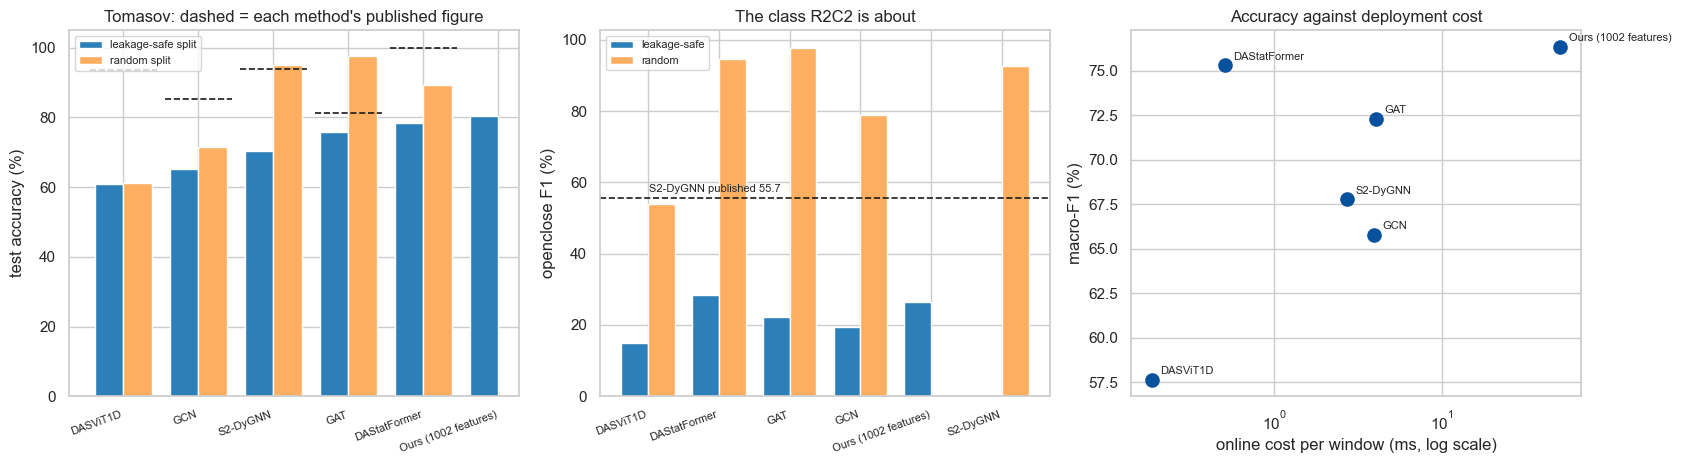

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

ax = axes[0]
sub = full[full.dataset == "tomasov"]
piv = sub.pivot_table(index="model", columns="arm", values="accuracy")
piv = piv.sort_values(piv.columns[0])
x, w = np.arange(len(piv)), 0.38
if "A_blocked" in piv.columns:
    ax.bar(x - w/2, piv["A_blocked"], w, color="#2c7fb8", label="leakage-safe split")
if "B_random" in piv.columns:
    ax.bar(x + w/2, piv["B_random"], w, color="#fdae61", label="random split")
for i, m in enumerate(piv.index):
    p = PUBLISHED[(PUBLISHED.model == m) & (PUBLISHED.dataset == "tomasov")]
    if len(p):
        ax.plot([i - 0.45, i + 0.45], [p.accuracy.iloc[0]] * 2, "k--", lw=1.2)
ax.set_xticks(x); ax.set_xticklabels(piv.index, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("test accuracy (%)")
ax.set_title("Tomasov: dashed = each method's published figure")
ax.legend(fontsize=8)

ax = axes[1]
if len(oc):
    p2 = oc.pivot_table(index="model", columns="arm", values="openclose_f1")
    x2 = np.arange(len(p2))
    if "A_blocked" in p2.columns:
        ax.bar(x2 - w/2, p2["A_blocked"], w, color="#2c7fb8", label="leakage-safe")
    if "B_random" in p2.columns:
        ax.bar(x2 + w/2, p2["B_random"], w, color="#fdae61", label="random")
    ax.axhline(pub_oc, ls="--", color="k", lw=1.2)
    ax.text(0.02, pub_oc + 1.5, "S2-DyGNN published 55.7", fontsize=8)
    ax.set_xticks(x2); ax.set_xticklabels(p2.index, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("openclose F1 (%)")
ax.set_title("The class R2C2 is about")
ax.legend(fontsize=8)

ax = axes[2]
cost = full[(full.dataset == "tomasov") & (full.arm == "A_blocked")]
ax.scatter(cost["online_ms_per_window"], cost["f1_macro"], s=90, color="#08519c")
for r in cost.itertuples():
    if r.online_ms_per_window == r.online_ms_per_window:
        ax.annotate(r.model, (r.online_ms_per_window, r.f1_macro),
                    xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("online cost per window (ms, log scale)")
ax.set_ylabel("macro-F1 (%)")
ax.set_title("Accuracy against deployment cost")

plt.tight_layout()
save_fig(fig, "sota_head_to_head.png")
plt.show()

## 7. What the paper must say

**R1C4 and R2C1.** Replace the CNN-only comparison with
`head_to_head_under_our_protocol.csv`. It covers a dynamic graph network, two static graph
networks, a spectral transformer and a statistical transformer, all published in 2024 or
later, all trained on the full manifests with our preprocessing, our metrics and one shared
training budget. Report parameter count, model size, training time and online cost per
window alongside accuracy: our pipeline's 0.17 ms inference is not the whole story, because
multi-domain extraction adds roughly 145 ms per window on Tomasov, and that comparison is
the one an operator cares about.

State clearly which methods beat ours under our own partition. The contribution of this
paper is the protocol and the leakage evidence; it does not require our classifier to win.

**The discount argument.** `sota_protocol_inflation.csv` gives, per method, the accuracy
gained from a random split on identical rows. DAStatFormer's 99.93 and DASViT1D's 93.5 were
obtained under exactly that protocol, and the measured inflation is the correction.
S2-DyGNN is the exception: their five-window margin at a 2048 shift exceeds the window
length, so their 94.0 is **not** discountable on leakage grounds.

**R2C2.** `openclose_verdict.json` and `capability_correlation.json` decide the wording. If
any architecture recovers openclose on our partition, the sentence claiming the class cannot
be determined must go, replaced by a limitation of our spatial representation. If none does,
the claim survives but must be restated as conditional on the protocol.

**Honesty about the reimplementations.** `sota_assumptions.json` lists every value we
supplied ourselves, including the shared 30-epoch budget. Where a reconstruction
underperforms its published figure by more than the measured protocol inflation, say the
reconstruction is a lower bound rather than claiming a win.